# Proyecto 2 — Visualización reproducible en Python
### Análisis exploratorio del *World Happiness Report 2024*

**Curso:** Visualización I — Universidad Externado de Colombia
**Equipo:** EquipoX — *\[completar integrantes\]*
**Docentes:** Adriana Pineda – Paola Moreno
**Entrega:** lunes 26 de octubre de 2026, 11:59 p.m.

---

> Este notebook se lee como un **informe analítico**: las celdas Markdown
> articulan el argumento y el código permite verificarlo.


## 1. Audiencia y pregunta analítica

**Audiencia técnica:** _\[identificar el tipo de investigador, equipo técnico o unidad
de análisis; explicar brevemente su interés en la problemática\]_

**Pregunta analítica:** _\[formular la pregunta concreta que orienta el análisis;
debe poder responderse con las variables disponibles en el WHR 2024\]_

**Acción esperada de la audiencia:**

1. Comprender la pregunta analítica y las variables empleadas.
2. Examinar distribuciones, relaciones y diferencias entre países o grupos.
3. Explorar interactivamente observaciones o comparaciones relevantes.
4. Distinguir resultados observados, limitaciones y nuevas preguntas.
5. Reproducir el análisis a partir de los archivos entregados.

> ⚠️ Las asociaciones observadas **no** se presentan como relaciones causales.


## 2. Datos: fuente y variables

**Fuente obligatoria:** World Happiness Report 2024 – *Data for Figure 2.1*
**Archivo oficial:** `WHR24_Data_Figure_2.1.xls`
**Descarga:** <https://files.worldhappiness.report/WHR24_Data_Figure_2.1.xls>

El archivo original se conserva sin modificaciones en `01_datos_originales/`.
Todas las operaciones de preparación se documentan por separado, de modo que
el procedimiento sea reproducible.


In [1]:
# ============================================================
# Celda 1 — Importación de librerías
# ============================================================
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.io as pio

# Configuración general de estilo
sns.set_theme(style="whitegrid", context="notebook")
pio.templates.default = "plotly_white"
pd.set_option("display.max_columns", 50)

RANDOM_STATE = 42  # para cualquier operación estocástica
print("Librerías importadas correctamente.")

Librerías importadas correctamente.


In [2]:
# ============================================================
# Celda 2 — Importación del archivo oficial
# ============================================================
# Ruta relativa: el notebook se ejecuta desde 02_notebook/
DATA_PATH = os.path.join("..", "01_datos_originales", "WHR24_Data_Figure_2.1.xls")

df = pd.read_excel(DATA_PATH)
print(f"Dimensiones: {df.shape[0]} filas x {df.shape[1]} columnas")
df.head()

Dimensiones: 143 filas x 11 columnas


,Country name,Ladder score,upperwhisker,lowerwhisker,Explained by: Log GDP per capita,Explained by: Social support,Explained by: Healthy life expectancy,Explained by: Freedom to make life choices,Explained by: Generosity,Explained by: Perceptions of corruption,Dystopia + residual
0,Finland,7.7407,7.814808,7.666591,1.844054,1.572367,0.694793,0.859294,0.141674,0.546158,2.082367
1,Denmark,7.5827,7.665297,7.500103,1.907798,1.520361,0.698944,0.822740,0.203579,0.548413,1.880887
2,Iceland,7.5251,7.617527,7.432673,1.880718,1.616525,0.718345,0.818509,0.258344,0.182473,2.050233
3,Sweden,7.3441,7.421563,7.266637,1.878146,1.500826,0.723871,0.838269,0.221455,0.523795,1.657707
4,Israel,7.3411,7.405165,7.277036,1.802934,1.512793,0.739816,0.641463,0.153205,0.192823,2.298026


### 2.1 Inspección de estructura, tipos y valores faltantes

_Primera verificación de reproducibilidad: qué hay en el archivo, de qué tipo es y
dónde faltan datos._

In [3]:
# ============================================================
# Celda 3 — Inspección: tipos, faltantes y estadísticas descriptivas
# ============================================================
print("=== Tipos de datos ===")
print(df.dtypes.to_string())
print("\n=== Valores faltantes ===")
faltantes = df.isna().sum()
print(faltantes[faltantes > 0].to_string() if (faltantes > 0).any() else "Sin valores faltantes")
print("\n=== Estadísticas descriptivas ===")
df.describe().T

=== Tipos de datos ===
Country name                                      str
Ladder score                                  float64
upperwhisker                                  float64
lowerwhisker                                  float64
Explained by: Log GDP per capita              float64
Explained by: Social support                  float64
Explained by: Healthy life expectancy         float64
Explained by: Freedom to make life choices    float64
Explained by: Generosity                      float64
Explained by: Perceptions of corruption       float64
Dystopia + residual                           float64

=== Valores faltantes ===
Explained by: Log GDP per capita              3
Explained by: Social support                  3
Explained by: Healthy life expectancy         3
Explained by: Freedom to make life choices    3
Explained by: Generosity                      3
Explained by: Perceptions of corruption       3
Dystopia + residual                           3

=== Estadísticas de

,count,mean,std,min,25%,50%,75%,max
Ladder score,143.0,5.527572,1.170690,1.721000,4.725700,5.785300,6.415850,7.740700
upperwhisker,143.0,5.641158,1.154980,1.775271,4.845570,5.894504,6.507774,7.814808
lowerwhisker,143.0,5.413986,1.187131,1.666728,4.605831,5.674096,6.319137,7.666591
Explained by: Log GDP per capita,140.0,1.378779,0.425085,0.000000,1.077373,1.431220,1.741240,2.140519
Explained by: Social support,140.0,1.134323,0.333309,0.000000,0.921409,1.237206,1.383399,1.616525
Explained by: Healthy life expectancy,140.0,0.520843,0.164949,0.000000,0.398097,0.549215,0.648200,0.857315
Explained by: Freedom to make life choices,140.0,0.620588,0.162499,0.000000,0.527390,0.641129,0.736312,0.863331
Explained by: Generosity,140.0,0.146327,0.073453,0.000000,0.091136,0.136315,0.192644,0.400811
Explained by: Perceptions of corruption,140.0,0.154123,0.126272,0.000000,0.068409,0.120141,0.193508,0.575109
Dystopia + residual,140.0,1.575896,0.537478,-0.072831,1.307982,1.644439,1.881608,2.997888


_**Observaciones de la inspección:** ¿cuántos países hay? ¿qué variables tienen
faltantes y en qué países? ¿las escalas son comparables entre sí?_

_\[completar tras ejecutar\]_

### 2.2 Diccionario de variables

| Variable | Significado | Uso en el análisis |
|----------|-------------|--------------------|
| `Country name` | País | Identificación / anotaciones |
| `Ladder score` | Evaluación de vida (0–10) | Variable de interés |
| `upperwhisker` / `lowerwhisker` | Intervalos del ladder score | Contexto de incertidumbre |
| `Explained by: Log GDP per capita` | Contribución del PIB per cápita | Indicador 1 |
| `Explained by: Social support` | Contribución del apoyo social | Indicador 2 |
| `Explained by: Healthy life expectancy` | Contribución de la esperanza de vida saludable | Indicador 3 |
| `Explained by: Freedom to make life choices` | Contribución de la libertad | Indicador 4 |
| `Explained by: Generosity` | Contribución de la generosidad | Indicador 5 |
| `Explained by: Perceptions of corruption` | Contribución de la percepción de corrupción | Indicador 6 |
| `Dystopia + residual` | Componente residual (Distopía + residual) | Contexto |

**Criterios de selección de variables, filtros y transformaciones** se documentan
en la celda de preparación (sección 3).

## 3. Preparación y alcance

En esta sección se deja **trazabilidad** de cada operación:

- criterios de selección de variables,
- filtros, agrupaciones o transformaciones,
- justificación de cualquier agrupación de países o indicador derivado.

La fuente original (`df`) se mantiene separada del conjunto preparado (`df_analisis`).

In [4]:
# ============================================================
# Celda 4 — Preparación documentada
# ============================================================
# 4.1 Renombrar columnas para trabajar con nombres cómodos (sin perder la trazabilidad)
renombrado = {
    "Country name": "pais",
    "Ladder score": "ladder_score",
    "Explained by: Log GDP per capita": "pib_percapita",
    "Explained by: Social support": "apoyo_social",
    "Explained by: Healthy life expectancy": "esperanza_vida",
    "Explained by: Freedom to make life choices": "libertad",
    "Explained by: Generosity": "generosidad",
    "Explained by: Perceptions of corruption": "corrupcion",
    "Dystopia + residual": "distopia_residual",
}

df_analisis = df.rename(columns=renombrado).copy()

# 4.2 Documentar filas con faltantes (NO se eliminan silenciosamente)
faltantes_mask = df_analisis.isna().any(axis=1)
print("Países con valores faltantes en indicadores:")
print(df_analisis.loc[faltantes_mask, ["pais"]].to_string(index=False))

# 4.3 Lista de indicadores que se usarán en el análisis
indicadores = ["pib_percapita", "apoyo_social", "esperanza_vida",
               "libertad", "generosidad", "corrupcion"]

# 4.4 Manejo explícito de faltantes: se documenta y se excluyen solo de las
#     visualizaciones que requieren valores completos (nunca en silencio).
n_faltantes = int(faltantes_mask.sum())
print(f"\nFilas con algún faltante: {n_faltantes} de {len(df_analisis)}")
print("Se conservan en 'df_analisis' y se excluyen con dropna() en las gráficas "
      "que lo requieren (p. ej. Plotly con 'size').")

# 4.5 (Opcional) Crear grupos de países JUSTIFICADOS si la pregunta lo requiere.
#      Ejemplo: terciles de ladder_score — documentar siempre el criterio.
df_analisis["grupo_bienestar"] = pd.qcut(
    df_analisis["ladder_score"], q=3,
    labels=["Bajo", "Medio", "Alto"]
)

print(f"\nConjunto preparado: {df_analisis.shape}")
df_analisis[["pais", "ladder_score", "grupo_bienestar"]].head()

Países con valores faltantes en indicadores:
              pais
           Bahrain
        Tajikistan
State of Palestine

Filas con algún faltante: 3 de 143
Se conservan en 'df_analisis' y se excluyen con dropna() en las gráficas que lo requieren (p. ej. Plotly con 'size').

Conjunto preparado: (143, 12)


,pais,ladder_score,grupo_bienestar
0,Finland,7.7407,Alto
1,Denmark,7.5827,Alto
2,Iceland,7.5251,Alto
3,Sweden,7.3441,Alto
4,Israel,7.3411,Alto


_**Justificación de transformaciones:** ¿por qué renombrar?, ¿por qué qcut en
terciles?, ¿qué se hizo con los faltantes y por qué?_

_\[completar con la justificación vinculada a la pregunta analítica\]_

## 4. Análisis exploratorio (EDA) y planificación de comparaciones

Antes de graficar, se planifica: **¿qué necesita examinar el analista con cada
visualización?, ¿por qué es adecuada para las variables?, ¿qué aporta que no se
haya mostrado ya?**

In [5]:
# ============================================================
# Celda 5 — EDA numérico: distribuciones y correlaciones base
# ============================================================
# 5.1 Estadísticas por indicador
resumen = df_analisis[indicadores + ["ladder_score"]].describe().T
display(resumen)

# 5.2 Matriz de correlación (base para elegir qué relaciones graficar)
corr = df_analisis[indicadores + ["ladder_score"]].corr()
display(corr.round(2))

# 5.3 Ranking extremos del ladder score (contexto para anotaciones)
print("Top 5 países:")
display(df_analisis.nlargest(5, "ladder_score")[["pais", "ladder_score"]])
print("Bottom 5 países:")
display(df_analisis.nsmallest(5, "ladder_score")[["pais", "ladder_score"]])

,count,mean,std,min,25%,50%,75%,max
pib_percapita,140.0,1.378779,0.425085,0.000,1.077373,1.431220,1.741240,2.140519
apoyo_social,140.0,1.134323,0.333309,0.000,0.921409,1.237206,1.383399,1.616525
esperanza_vida,140.0,0.520843,0.164949,0.000,0.398097,0.549215,0.648200,0.857315
libertad,140.0,0.620588,0.162499,0.000,0.527390,0.641129,0.736312,0.863331
generosidad,140.0,0.146327,0.073453,0.000,0.091136,0.136315,0.192644,0.400811
corrupcion,140.0,0.154123,0.126272,0.000,0.068409,0.120141,0.193508,0.575109
ladder_score,143.0,5.527572,1.170690,1.721,4.725700,5.785300,6.415850,7.740700


,pib_percapita,apoyo_social,esperanza_vida,libertad,generosidad,corrupcion,ladder_score
pib_percapita,1.00,0.73,0.83,0.41,-0.06,0.44,0.77
apoyo_social,0.73,1.00,0.71,0.48,0.08,0.25,0.81
esperanza_vida,0.83,0.71,1.00,0.40,0.01,0.40,0.76
libertad,0.41,0.48,0.40,1.00,0.22,0.34,0.64
generosidad,-0.06,0.08,0.01,0.22,1.00,0.17,0.13
corrupcion,0.44,0.25,0.40,0.34,0.17,1.00,0.45
ladder_score,0.77,0.81,0.76,0.64,0.13,0.45,1.00


Top 5 países:


,pais,ladder_score
0,Finland,7.7407
1,Denmark,7.5827
2,Iceland,7.5251
3,Sweden,7.3441
4,Israel,7.3411


Bottom 5 países:


,pais,ladder_score
142,Afghanistan,1.7210
141,Lebanon,2.7065
140,Lesotho,3.1862
139,Sierra Leone,3.2452
138,Congo (Kinshasa),3.2954


### 4.1 Plan de visualizaciones

| # | Tipo | Librería | Qué examina | Propósito analítico |
|---|------|----------|-------------|---------------------|
| 1 | Distribución | Seaborn | Ladder score global | Forma y dispersiones iniciales |
| 2 | Relación | Seaborn | Indicador vs ladder score | Asociaciones individuales |
| 3 | Comparación de grupos | Seaborn | Grupos de bienestar × indicadores | Diferencias entre grupos |
| 4 | Matriz / anotaciones | Seaborn | Correlaciones + casos extremos | Panorama general con lectura |
| 5 | Interactiva 1 | Plotly | Exploración país-indicador | Profundizar en observaciones |
| 6 | Interactiva 2 | Plotly | Comparación multivariable | Exploración con filtro/agrupación |

_Cada visualización se acompaña inmediatamente de su interpretación escrita,
vinculada a la pregunta analítica._

## 5. Visualizaciones estáticas con Seaborn

> **Mínimo requerido: 4 gráficos.** Cada uno responde: ¿qué necesita examinar el
> analista?, ¿por qué esta forma es adecuada?, ¿qué aporta que no se mostró ya?

### 5.1 — Visualización estática 1: distribución del ladder score

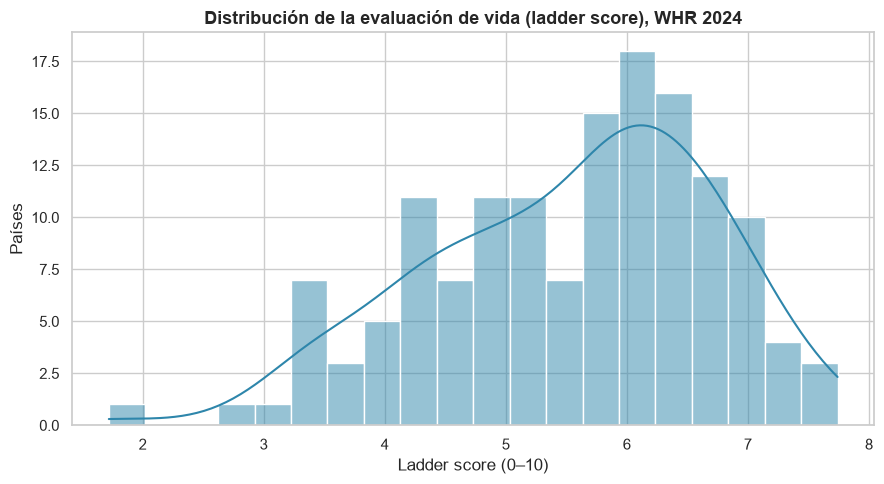

In [6]:
# ============================================================
# Celda 6 — Seaborn 1: distribución del ladder score
# ============================================================
fig, ax = plt.subplots(figsize=(9, 5))

sns.histplot(data=df_analisis, x="ladder_score", kde=True, bins=20,
             color="#2E86AB", ax=ax)

ax.set_title("Distribución de la evaluación de vida (ladder score), WHR 2024",
             fontsize=13, fontweight="bold")
ax.set_xlabel("Ladder score (0–10)")
ax.set_ylabel("Países")

plt.tight_layout()
plt.show()

**Interpretación (Visualización 1):**

_¿Cómo se distribuye la evaluación de vida entre los 143 países? ¿Hay sesgo,
valores atípicos o diferencias claras? ¿Qué indica esto para la pregunta
analítica?_

_\[escribir aquí la lectura, conectada explícitamente con la pregunta\]_

### 5.2 — Visualización estática 2: asociación entre un indicador y el ladder score

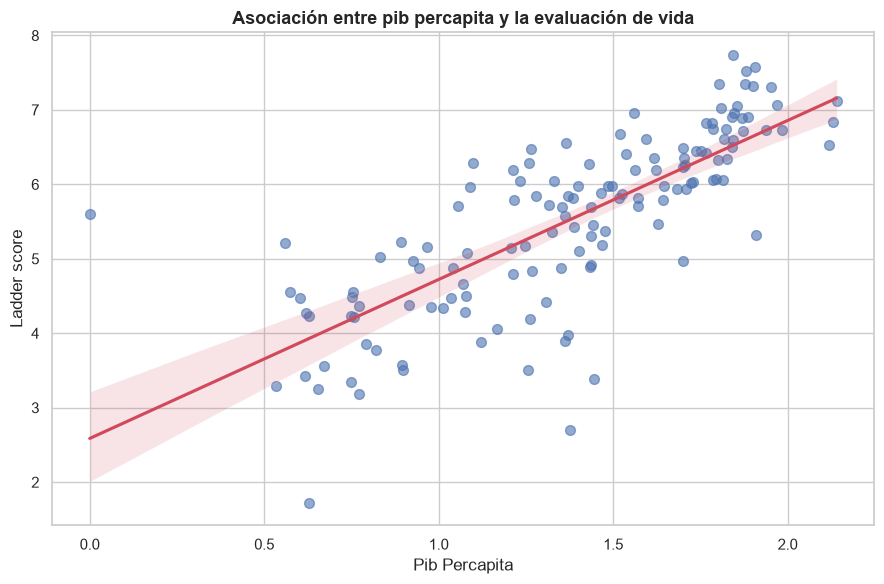

In [7]:
# ============================================================
# Celda 7 — Seaborn 2: indicador vs ladder score
# ============================================================
# AJUSTAR: elegir el indicador más pertinente para la pregunta analítica
VAR_X = "pib_percapita"   # <- cambiar según la pregunta

fig, ax = plt.subplots(figsize=(9, 6))

sns.regplot(data=df_analisis, x=VAR_X, y="ladder_score",
            scatter_kws={"alpha": 0.6, "s": 50},
            line_kws={"color": "#D1495B"}, ax=ax)

ax.set_title(f"Asociación entre {VAR_X.replace('_', ' ')} y la evaluación de vida",
             fontsize=13, fontweight="bold")
ax.set_xlabel(VAR_X.replace("_", " ").title())
ax.set_ylabel("Ladder score")

plt.tight_layout()
plt.show()

**Interpretación (Visualización 2):**

_¿La asociación es positiva/negativa?, ¿cuál es su fuerza?, ¿hay países atípicos?
Esto es una **asociación observada, no causalidad**. ¿Qué aporta para responder
la pregunta?_

_\[escribir aquí\]_

### 5.3 — Visualización estática 3: comparación entre grupos de países

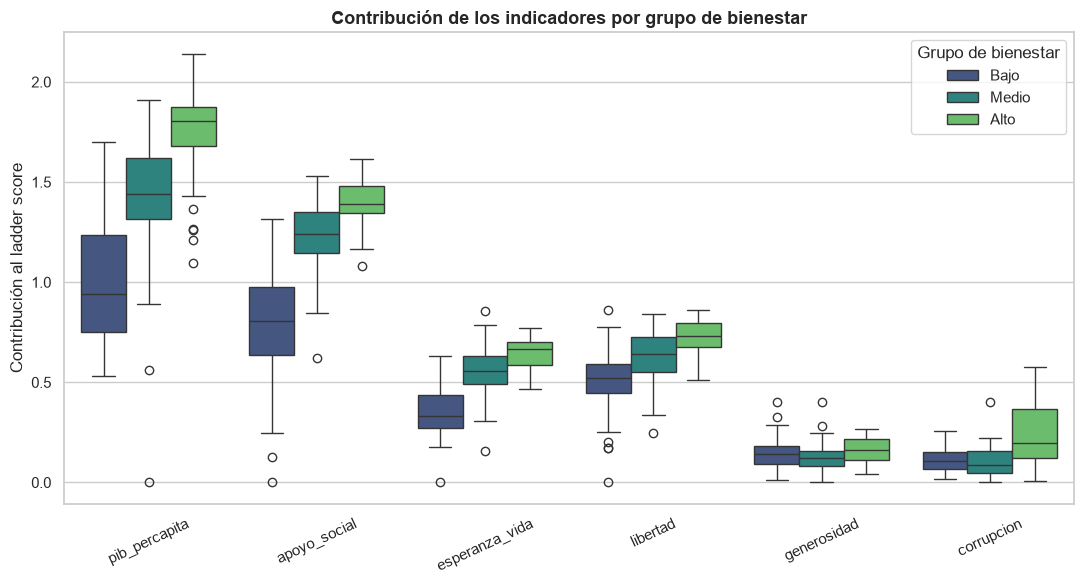

In [8]:
# ============================================================
# Celda 8 — Seaborn 3: indicadores por grupo de bienestar
# ============================================================
# Comparación de TODOS los indicadores entre grupos justificados (terciles)
melted = df_analisis.melt(
    id_vars=["pais", "grupo_bienestar", "ladder_score"],
    value_vars=indicadores,
    var_name="indicador", value_name="contribucion"
)

fig, ax = plt.subplots(figsize=(11, 6))

sns.boxplot(data=melted, x="indicador", y="contribucion",
            hue="grupo_bienestar", palette="viridis", ax=ax)

ax.set_title("Contribución de los indicadores por grupo de bienestar",
             fontsize=13, fontweight="bold")
ax.set_xlabel("")
ax.set_ylabel("Contribución al ladder score")
ax.tick_params(axis="x", rotation=25)
ax.legend(title="Grupo de bienestar")

plt.tight_layout()
plt.show()

**Interpretación (Visualización 3):**

_¿Qué indicadores varían más entre grupos bajos, medios y altos? ¿Hay solapamiento?
¿La comparación de grupos está justificada por la pregunta analítica?_

_\[escribir aquí\]_

### 5.4 — Visualización estática 4: panorama de correlaciones con anotaciones

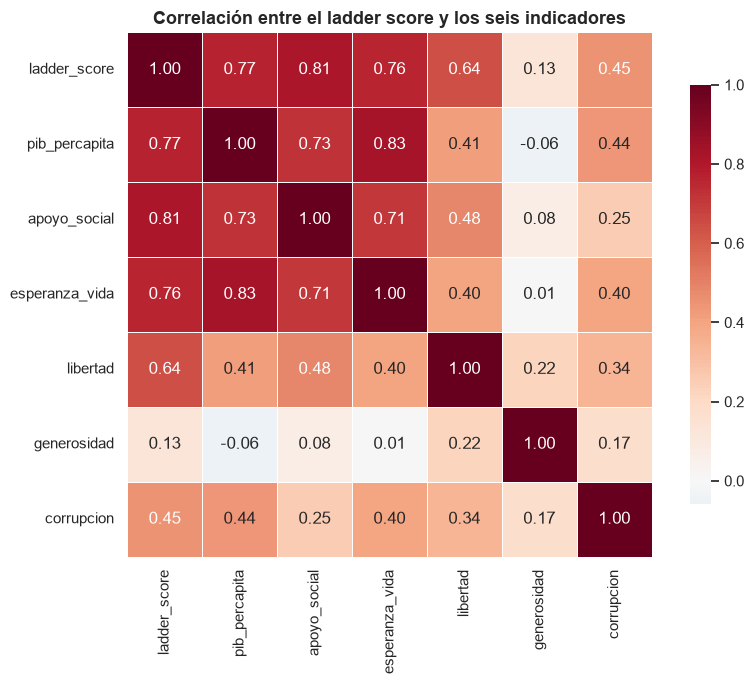

In [9]:
# ============================================================
# Celda 9 — Seaborn 4: heatmap de correlaciones
# ============================================================
cols_corr = ["ladder_score"] + indicadores
corr = df_analisis[cols_corr].corr()

fig, ax = plt.subplots(figsize=(9, 7))

sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            square=True, linewidths=.5, cbar_kws={"shrink": .8}, ax=ax)

ax.set_title("Correlación entre el ladder score y los seis indicadores",
             fontsize=13, fontweight="bold")

plt.tight_layout()
plt.show()

**Interpretación (Visualización 4):**

_¿Qué indicadores tienen la correlación más fuerte con el ladder score?, ¿hay
colinealidad entre indicadores?, ¿qué relaciones merecen explorarse en detalle
con Plotly?_

_\[escribir aquí\]_

## 6. Visualizaciones interactivas con Plotly

> **Mínimo requerido: 2 gráficos** con propósitos analíticos diferenciados. La
> interactividad debe **aportar valor** a la interpretación: permitir profundizar
> en observaciones o comparaciones, no solo añadir efectos visuales.

### 6.1 — Interactiva 1: exploración país-indicador

In [10]:
# ============================================================
# Celda 10 — Plotly 1: burbujas (o scatter interactivo) país-indicador
# ============================================================
# AJUSTAR: elegir ejes y variable de tamaño según la pregunta analítica
# Se excluyen filas con faltantes SOLO para este gráfico (dropna documentado)
df_plot1 = df_analisis.dropna(subset=["esperanza_vida", "ladder_score", "pib_percapita"])

fig1 = px.scatter(
    df_plot1,
    x="esperanza_vida",           # <- ajustar
    y="ladder_score",
    size="pib_percapita",         # <- ajustar (tamaño = tercer indicador)
    color="grupo_bienestar",
    hover_name="pais",
    hover_data={"ladder_score": ":.2f", "esperanza_vida": ":.2f"},
    labels={
        "esperanza_vida": "Contribución esperanza de vida saludable",
        "ladder_score": "Ladder score",
        "grupo_bienestar": "Grupo de bienestar",
        "pib_percapita": "PIB per cápita (log)",
    },
    title="Evaluación de vida vs. esperanza de vida saludable (tamaño: PIB per cápita)",
    color_discrete_sequence=px.colors.qualitative.Set2,
    size_max=22,
    opacity=0.75,
)

fig1.update_layout(height=560, legend_title_text="Grupo de bienestar")
fig1.show()

**Interpretación (Interactiva 1):**

_¿Qué permite examinar la interacción que un gráfico estático no mostraba?
(hover por país, tamaño como tercer indicador, filtro por grupo). ¿Qué patrones
o casos atípicos aparecen al explorar? ¿Qué aporta para la pregunta?_

_\[escribir aquí\]_

### 6.2 — Interactiva 2: comparación con filtro

In [11]:
# ============================================================
# Celda 11 — Plotly 2: barras interactivo con selector de indicador
# ============================================================
# Versión larga con el indicador como NIVEL (para el slider de animation_frame)
melted2 = df_analisis.melt(
    id_vars=["pais", "grupo_bienestar", "ladder_score"],
    value_vars=indicadores,
    var_name="indicador", value_name="contribucion"
)

# Top 15 por indicador (sin drop de la columna 'indicador')
top_por_indicador = (
    melted2.dropna(subset=["contribucion"])
    .sort_values("contribucion", ascending=False)
    .groupby("indicador", group_keys=True, observed=True)
    .head(15)
    .reset_index(drop=True)
)

fig2 = px.bar(
    top_por_indicador,
    x="contribucion", y="pais",
    color="grupo_bienestar",
    animation_frame="indicador",          # <- filtro/selector: recorre indicadores
    labels={"contribucion": "Contribución", "pais": "País",
            "grupo_bienestar": "Grupo de bienestar"},
    title="Top 15 países por contribución — seleccione el indicador",
    color_discrete_sequence=px.colors.qualitative.Pastel,
    orientation="h",
)

fig2.update_layout(height=600, yaxis={"categoryorder": "total ascending"},
                   legend_title_text="Grupo de bienestar")
fig2.show()

**Interpretación (Interactiva 2):**

_¿Qué comparación habilita el filtro/selector que no era posible en estático?
¿Qué hallazgos emergen al recorrer los indicadores? ¿La interactividad aporta
valor analítico o solo decoración?_

_\[escribir aquí\]_

## 7. Síntesis de hallazgos y conclusiones

**Respuesta a la pregunta analítica:**

_\[integrar la evidencia de las seis visualizaciones para responder la pregunta
planteada en la sección 1. Cada hallazgo debe estar sustentado en los gráficos
anteriores.\]_

**Limitaciones del análisis:**

- _[alcance de la fuente: un solo año, indicadores agregados]_
- _[asociación ≠ causalidad]_
- _[faltantes / agrupaciones utilizadas]_
- _[otras que identifique el equipo]_

**Nuevas preguntas de investigación:**

- _[1]_
- _[2]_

## 8. Comprobación de reproducibilidad

Ejecutar **Run All** desde el inicio: el notebook debe correr completo, sin
ajustes manuales, con rutas relativas y sin dependencias ocultas.

In [12]:
# ============================================================
# Celda 12 — Verificación final de reproducibilidad
# ============================================================
print("Reproducibilidad — verificación final")
print(f"  1. Datos originales leídos: {os.path.exists(DATA_PATH)}")
print(f"  2. Filas en el dataset:    {df.shape[0]}")
print(f"  3. Filas preparadas:       {df_analisis.shape[0]}")
print(f"  4. Seaborn (mín. 4):       [indicar cuáles celdas] ")
print(f"  5. Plotly (mín. 2):        [indicar cuáles celdas] ")
print("  6. Entregables: notebook + HTML Plotly + PDF (3 pág.) + anexo IA (1 pág.)")
print("\n✓ Notebook ejecutado de principio a fin.")

Reproducibilidad — verificación final
  1. Datos originales leídos: True
  2. Filas en el dataset:    143
  3. Filas preparadas:       143
  4. Seaborn (mín. 4):       [indicar cuáles celdas] 
  5. Plotly (mín. 2):        [indicar cuáles celdas] 
  6. Entregables: notebook + HTML Plotly + PDF (3 pág.) + anexo IA (1 pág.)

✓ Notebook ejecutado de principio a fin.


## 9. Anexo técnico de uso de IA (resumen)

> **Nota:** el anexo completo se entrega como PDF de máximo **una página**
> (`EquipoX_Proyecto2_Anexo_IA.pdf`). Este bloque es el borrador de trabajo.

**Herramientas y propósito:** _\[cuál y para qué\]_

**Prompts empleados (incluido al menos uno sobre la paleta de colores):**

1. _\[prompt sobre paleta de colores\]_
2. _\[otros prompts\]_

**Reflexión sobre revisión crítica:** _\[qué se verificó, qué se corrigió, qué se
rechazó de la salida de la IA\]_

_Si no se utilizó IA, declararlo expresamente._